<a href="https://colab.research.google.com/github/Anet-Bino/Web_Traffic_Analytics/blob/main/Web_Traffic_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd

# Load the dataset
df = pd.read_csv('/content/website-traffic-1000.csv')

# Display first five rows
df.head()


,date,channel,sessions,users,new_users,pageviews,avg_session_seconds,bounce_rate,conversions,revenue
0,2024-01-01,Organic search,446,356,225,1026,205,0.527,7,442.83
1,2024-01-01,Direct,244,209,71,707,255,0.555,10,710.96
2,2024-01-01,Referral,87,77,52,207,104,0.377,2,82.20
3,2024-01-01,Social,156,140,92,438,179,0.323,2,94.43
4,2024-01-01,Email,61,54,31,205,148,0.349,3,161.46


In [3]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
df.describe()


Dataset Shape: (1000, 10)

Column Names:
['date', 'channel', 'sessions', 'users', 'new_users', 'pageviews', 'avg_session_seconds', 'bounce_rate', 'conversions', 'revenue']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 1000 non-null   object 
 1   channel              1000 non-null   object 
 2   sessions             1000 non-null   int64  
 3   users                1000 non-null   int64  
 4   new_users            1000 non-null   int64  
 5   pageviews            1000 non-null   int64  
 6   avg_session_seconds  1000 non-null   int64  
 7   bounce_rate          1000 non-null   float64
 8   conversions          1000 non-null   int64  
 9   revenue              1000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 78.3+ KB

Statistical Summary:


,sessions,users,new_users,pageviews,avg_session_seconds,bounce_rate,conversions,revenue
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.0000,1000.000000
mean,186.430000,156.143000,86.833000,461.805000,166.791000,0.470917,4.6960,260.090100
std,127.408218,106.608329,63.508995,332.065983,55.795829,0.088137,3.3928,195.499667
min,45.000000,37.000000,22.000000,74.000000,70.000000,0.321000,1.0000,38.540000
25%,90.000000,77.000000,47.000000,218.000000,117.000000,0.394750,2.0000,117.827500
50%,135.500000,115.000000,65.000000,330.000000,168.000000,0.469000,3.0000,183.065000
75%,272.000000,227.000000,88.000000,612.250000,216.000000,0.550250,7.0000,387.655000
max,551.000000,468.000000,315.000000,1691.000000,260.000000,0.620000,14.0000,916.020000


In [4]:

# Check missing values in each column
print(df.isnull().sum())


date                   0
channel                0
sessions               0
users                  0
new_users              0
pageviews              0
avg_session_seconds    0
bounce_rate            0
conversions            0
revenue                0
dtype: int64


In [5]:

# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [6]:

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

print("Dataset after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicates:", df.duplicated().sum())


Dataset after cleaning: (1000, 10)
Remaining missing values: 0
Remaining duplicates: 0


In [7]:

# Display all column names
print(df.columns.tolist())


['date', 'channel', 'sessions', 'users', 'new_users', 'pageviews', 'avg_session_seconds', 'bounce_rate', 'conversions', 'revenue']


In [8]:

# Calculate important website traffic metrics

total_sessions = df['sessions'].sum()
total_users = df['users'].sum()
total_pageviews = df['pageviews'].sum()
avg_duration = df['avg_session_seconds'].mean()
avg_bounce_rate = df['bounce_rate'].mean()
total_conversions = df['conversions'].sum()
total_revenue = df['revenue'].sum()

print("WEBSITE TRAFFIC ANALYSIS")
print("------------------------")
print("Total Sessions:", total_sessions)
print("Total Users:", total_users)
print("Total Page Views:", total_pageviews)
print("Average Session Duration:", round(avg_duration, 2), "seconds")
print("Average Bounce Rate:", round(avg_bounce_rate, 2), "%")
print("Total Conversions:", total_conversions)
print("Total Revenue:", round(total_revenue, 2))


WEBSITE TRAFFIC ANALYSIS
------------------------
Total Sessions: 186430
Total Users: 156143
Total Page Views: 461805
Average Session Duration: 166.79 seconds
Average Bounce Rate: 0.47 %
Total Conversions: 4696
Total Revenue: 260090.1


In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


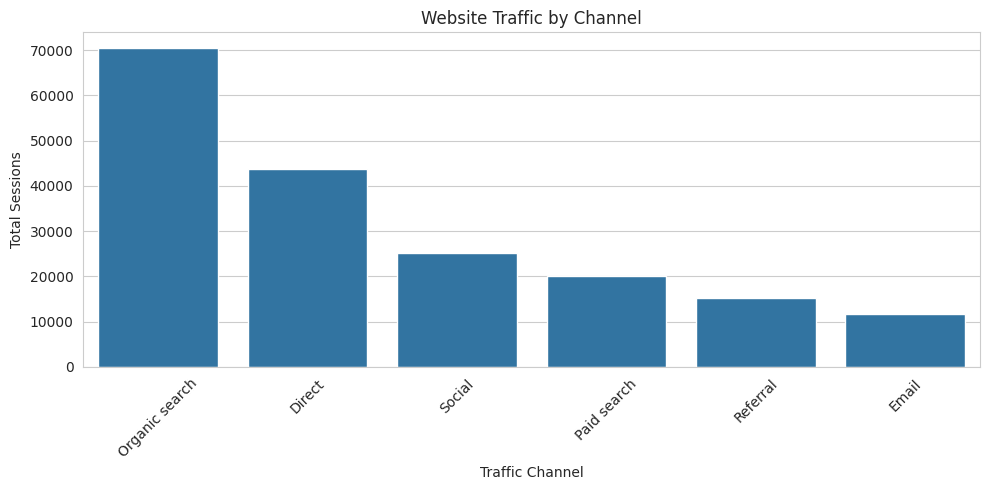

In [10]:

# Calculate sessions for each channel
channel_traffic = df.groupby('channel')['sessions'].sum().sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(10,5))
sns.barplot(x=channel_traffic.index, y=channel_traffic.values)

plt.title("Website Traffic by Channel")
plt.xlabel("Traffic Channel")
plt.ylabel("Total Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [11]:

# Convert date column into datetime format
df['date'] = pd.to_datetime(df['date'])

print(df['date'].head())


0   2024-01-01
1   2024-01-01
2   2024-01-01
3   2024-01-01
4   2024-01-01
Name: date, dtype: datetime64[ns]


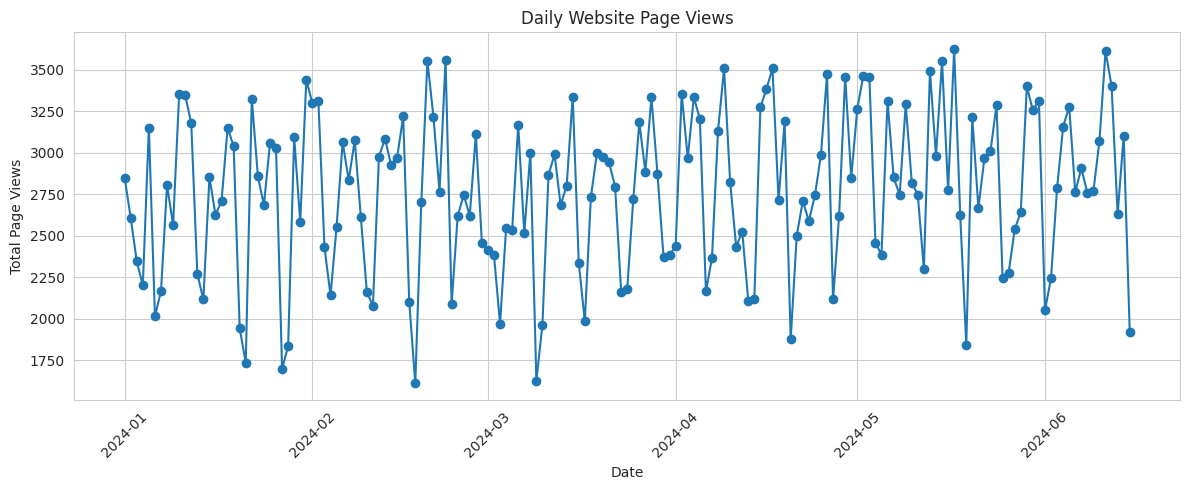

In [12]:

# Calculate page views by date
daily_views = df.groupby('date')['pageviews'].sum()

# Create line chart
plt.figure(figsize=(12,5))
plt.plot(daily_views.index, daily_views.values, marker='o')

plt.title("Daily Website Page Views")
plt.xlabel("Date")
plt.ylabel("Total Page Views")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Average Session Duration: 2.78 minutes


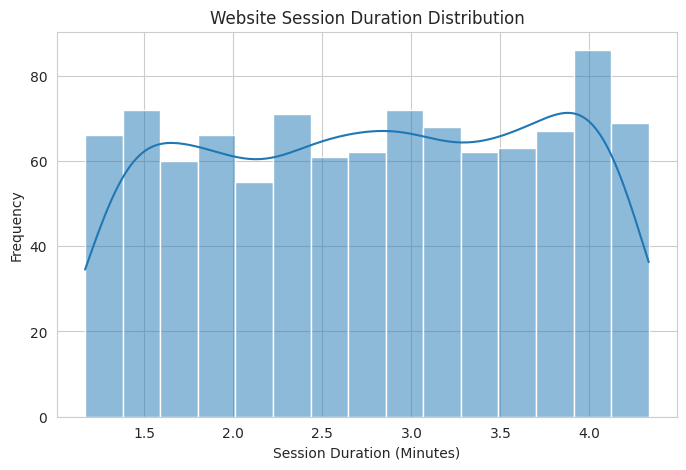

In [13]:

# Convert session duration from seconds to minutes
df['session_duration_minutes'] = df['avg_session_seconds'] / 60

# Calculate average session duration
avg_time = df['session_duration_minutes'].mean()

print("Average Session Duration:", round(avg_time, 2), "minutes")

# Visualize session duration
plt.figure(figsize=(8,5))
sns.histplot(df['session_duration_minutes'], bins=15, kde=True)

plt.title("Website Session Duration Distribution")
plt.xlabel("Session Duration (Minutes)")
plt.ylabel("Frequency")
plt.show()


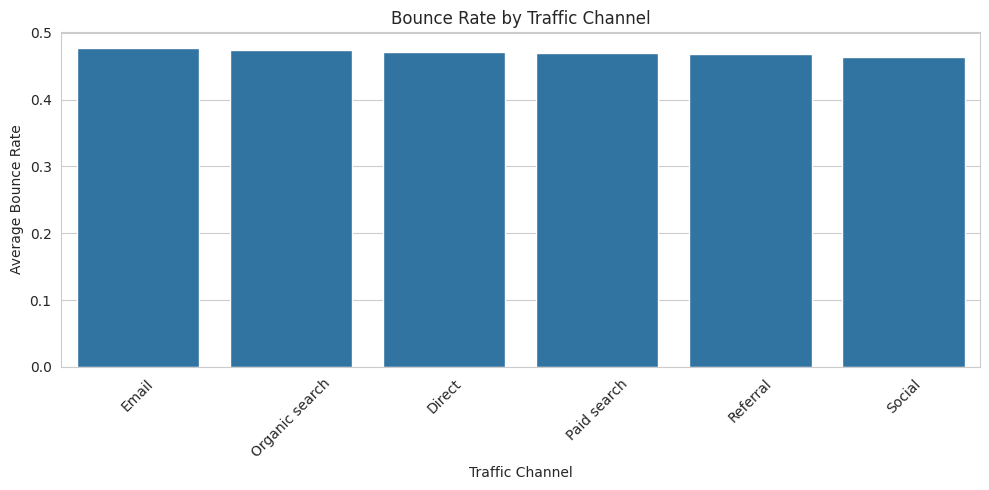

In [14]:

# Calculate average bounce rate by channel
bounce_by_channel = df.groupby('channel')['bounce_rate'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(x=bounce_by_channel.index, y=bounce_by_channel.values)

plt.title("Bounce Rate by Traffic Channel")
plt.xlabel("Traffic Channel")
plt.ylabel("Average Bounce Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

# Calculate conversions for each channel
conversion_data = df.groupby('channel')['conversions'].sum().sort_values(ascending=False)

print("Conversions by Traffic Channel:")
print(conversion_data)


Conversions by Traffic Channel:
channel
Organic search    1498
Direct            1497
Paid search        581
Email              488
Referral           404
Social             228
Name: conversions, dtype: int64


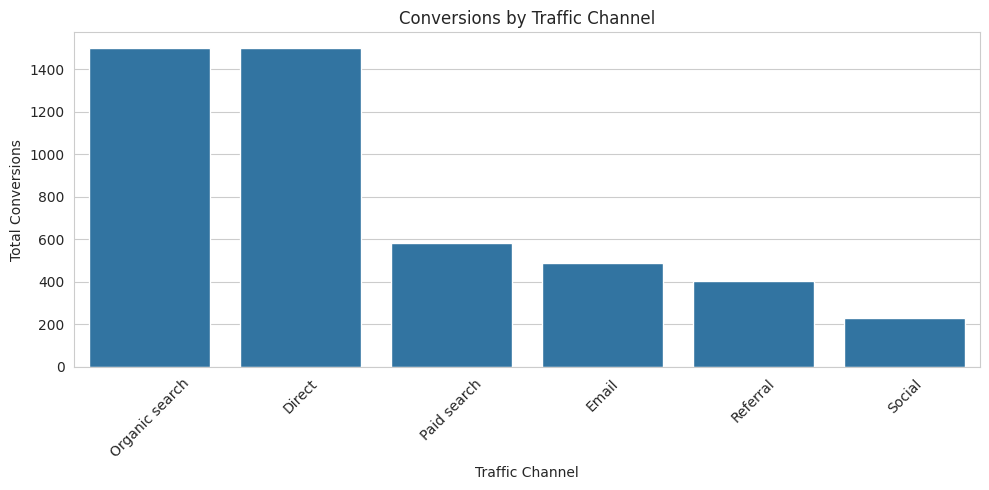

In [16]:

plt.figure(figsize=(10,5))

sns.barplot(x=conversion_data.index, y=conversion_data.values)

plt.title("Conversions by Traffic Channel")
plt.xlabel("Traffic Channel")
plt.ylabel("Total Conversions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


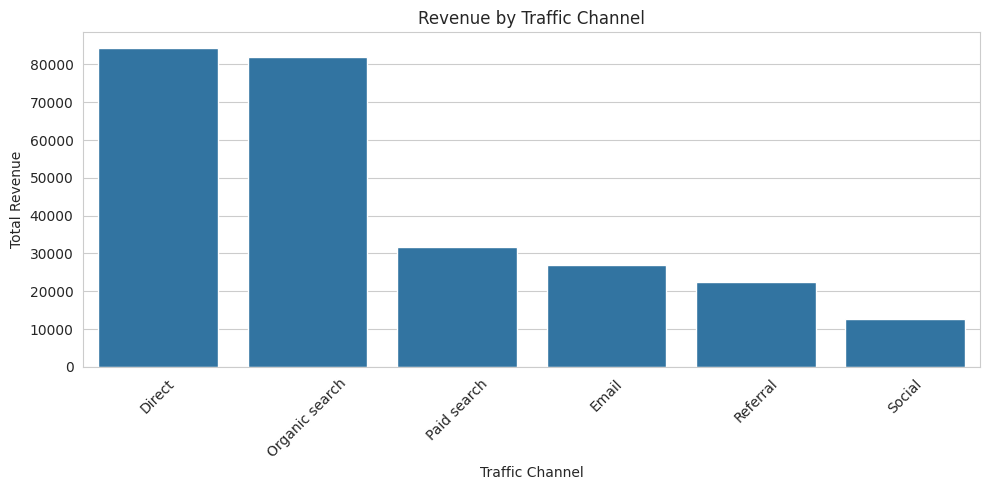

In [17]:

revenue_data = df.groupby('channel')['revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(x=revenue_data.index, y=revenue_data.values)

plt.title("Revenue by Traffic Channel")
plt.xlabel("Traffic Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [18]:

# Calculate average bounce rate by channel
dropoff = df.groupby('channel')['bounce_rate'].mean().sort_values(ascending=False)

print("User Drop-off Analysis:")
print(dropoff)


User Drop-off Analysis:
channel
Email             0.476849
Organic search    0.474533
Direct            0.471503
Paid search       0.469373
Referral          0.468994
Social            0.464275
Name: bounce_rate, dtype: float64


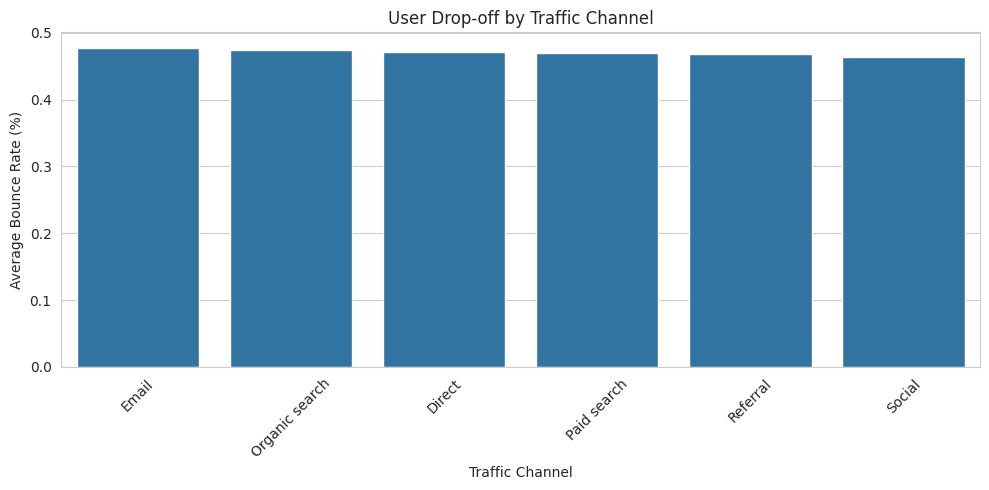

In [19]:

plt.figure(figsize=(10,5))

sns.barplot(x=dropoff.index, y=dropoff.values)

plt.title("User Drop-off by Traffic Channel")
plt.xlabel("Traffic Channel")
plt.ylabel("Average Bounce Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [21]:

highest_dropoff = dropoff.idxmax()

print("Channel with Highest Drop-off:", highest_dropoff)
print("Bounce Rate:", round(dropoff.max(), 2), "%")


Channel with Highest Drop-off: Email
Bounce Rate: 0.48 %


In [22]:

# Website Traffic Summary

print("========== WEBSITE TRAFFIC SUMMARY ==========")

print("\n1. Total Sessions:", df['sessions'].sum())

print("2. Total Users:", df['users'].sum())

print("3. Total Page Views:", df['pageviews'].sum())

print("4. Average Session Duration:",
      round(df['avg_session_seconds'].mean() / 60, 2), "minutes")

print("5. Average Bounce Rate:",
      round(df['bounce_rate'].mean(), 2), "%")

print("6. Total Conversions:", df['conversions'].sum())

print("7. Total Revenue:", round(df['revenue'].sum(), 2))

print("\n8. Best Traffic Channel:",
      channel_traffic.idxmax())

print("9. Highest Drop-off Channel:",
      dropoff.idxmax())

print("==============================================")


========== WEBSITE TRAFFIC SUMMARY ==========

1. Total Sessions: 186430
2. Total Users: 156143
3. Total Page Views: 461805
4. Average Session Duration: 2.78 minutes
5. Average Bounce Rate: 0.47 %
6. Total Conversions: 4696
7. Total Revenue: 260090.1

8. Best Traffic Channel: Organic search
9. Highest Drop-off Channel: Email


## Conclusion – Web Traffic Analytics

The Web Traffic Analytics project was performed using Python in Google Colab.

The main objective was to understand website visitor behavior and analyze traffic patterns.

The project included:
- Analysis of total sessions, users and page views.
- Calculation of average session duration and bounce rate.
- Identification of popular traffic channels.
- Analysis of conversions and revenue.
- Identification of channels with higher bounce rates.
- Visualization of website traffic using graphs and charts.

**Recommendations:**
1. Improve website content to increase visitor engagement.
2. Optimize pages with high bounce rates.
3. Focus on traffic channels that generate more conversions.
4. Improve the user experience to encourage visitors to explore more pages.

This analysis helps understand website performance and supports better decisions to improve user engagement and retention.